# LeaseLens — Phase 5B: Exploratory Data Analysis & Data Preprocessing

**Notebook:** `01_eda_and_data_cleaning.ipynb`  
**Project:** LeaseLens (Intelligent Rental & Lease Management Platform)  
**Objective:** Perform comprehensive exploratory data analysis (EDA), audit data quality, validate empirical hypotheses, execute defensible cleaning rules, engineer structural features, and create a leak-free 80/20 train/test split for rental price regression in INR.

---

## 1. Setup & Environment
Import core numerical, analytical, and visualization libraries.


In [1]:
import os
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Add src to path
sys.path.append(os.path.join('..', 'src'))

# Locate raw dataset
raw_path = os.path.join('..', 'data', 'raw', 'House_Rent_Dataset.csv')
print(f'Raw dataset path: {raw_path}')
print(f'File exists: {os.path.exists(raw_path)}')


Raw dataset path: ..\data\raw\House_Rent_Dataset.csv
File exists: True


## 2. Raw Dataset Ingestion & Integrity Verification
Verify file size, SHA-256 cryptographic checksum, shape, and column data types.


In [2]:
with open(raw_path, 'rb') as f:
    sha256 = hashlib.sha256(f.read()).hexdigest()
size_bytes = os.path.getsize(raw_path)
print(f'File Size: {size_bytes} bytes (~{size_bytes / 1024:.2f} KB)')
print(f'SHA-256:   {sha256}')

df_raw = pd.read_csv(raw_path)
print(f'Dimensions: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')
print('\nColumns & Types:')
print(df_raw.dtypes)


File Size: 562214 bytes (~549.04 KB)
SHA-256:   5f55b1040cdd9e7e79881c17a2ba2ba204fd153a6bc4cd32fa64c7d2d97ae15f
Dimensions: 4746 rows x 12 columns

Columns & Types:
Posted On            object
BHK                   int64
Rent                  int64
Size                  int64
Floor                object
Area Type            object
Area Locality        object
City                 object
Furnishing Status    object
Tenant Preferred     object
Bathroom              int64
Point of Contact     object
dtype: object


## 3. Data Quality & Completeness Audit
Auditing missing values, duplicate rows, and near-duplicate listings.


In [3]:
print('--- Missing Values ---')
print(df_raw.isnull().sum())

print('\n--- Exact Duplicates (12 columns) ---')
print(df_raw.duplicated().sum())

feat_cols = [c for c in df_raw.columns if c != 'Posted On']
print('\n--- Duplicates Excluding Scraper Timestamp (Posted On) ---')
print(df_raw.duplicated(subset=feat_cols).sum())


--- Missing Values ---
Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

--- Exact Duplicates (12 columns) ---
0

--- Duplicates Excluding Scraper Timestamp (Posted On) ---
8


## 4. Target Variable Analysis (`Rent` in INR)
We examine the distribution of `Rent`, observe extreme positive skewness caused by ultra-luxury properties in Mumbai, and test whether `log1p` stabilizes error variance.


Rent Summary Statistics:
count    4.746000e+03
mean     3.499345e+04
std      7.810641e+04
min      1.200000e+03
25%      1.000000e+04
50%      1.600000e+04
75%      3.300000e+04
max      3.500000e+06
Name: Rent, dtype: float64
Skewness (Raw Rent):    21.4099
Skewness (log1p Rent):  0.9090


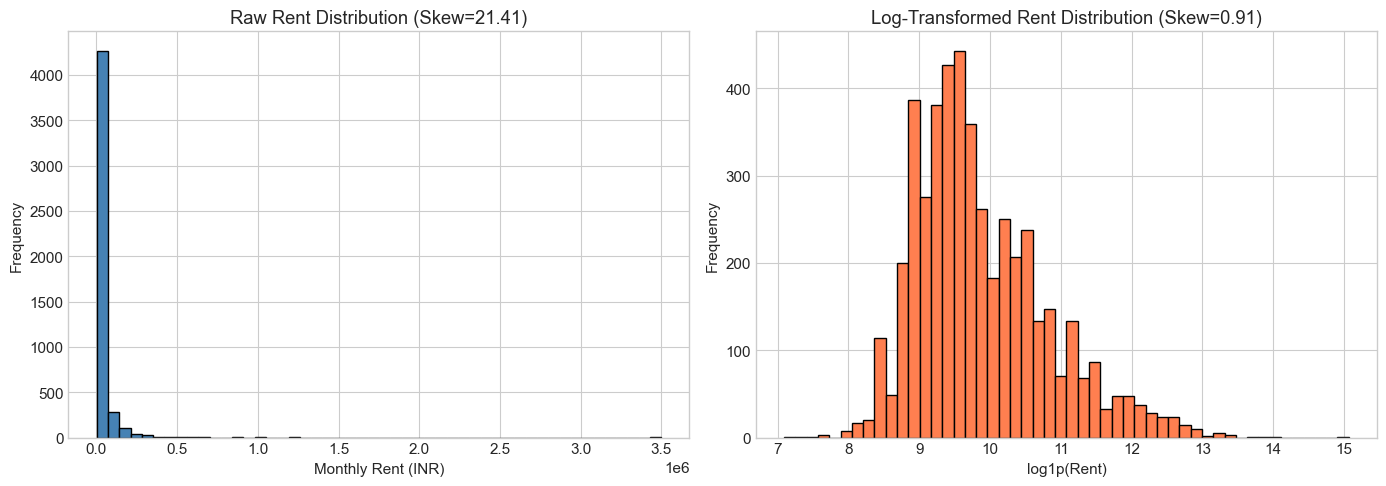

In [4]:
rent_s = df_raw['Rent']
print('Rent Summary Statistics:')
print(rent_s.describe())
print(f'Skewness (Raw Rent):    {rent_s.skew():.4f}')
print(f'Skewness (log1p Rent):  {np.log1p(rent_s).skew():.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(rent_s, bins=50, color='steelblue', edgecolor='black')
axes[0].set_title(f'Raw Rent Distribution (Skew={rent_s.skew():.2f})')
axes[0].set_xlabel('Monthly Rent (INR)')
axes[0].set_ylabel('Frequency')

axes[1].hist(np.log1p(rent_s), bins=50, color='coral', edgecolor='black')
axes[1].set_title(f'Log-Transformed Rent Distribution (Skew={np.log1p(rent_s).skew():.2f})')
axes[1].set_xlabel('log1p(Rent)')
axes[1].set_ylabel('Frequency')
plt.tight_layout()
plt.show()


## 5. Bivariate Relationships & Geographic Analysis
Analyzing rent distributions across the 6 metropolitan cities and relationship with BHK and unit size.


City-wise Rent Metrics:
           count   median          mean   min      max
City                                                  
Bangalore    886  14000.0  24966.365688  3500  3500000
Chennai      891  14000.0  21614.092031  3000   600000
Delhi        605  17000.0  29461.983471  2000   530000
Hyderabad    868  14000.0  20555.048387  1200   400000
Kolkata      524   8500.0  11645.173664  1500   180000
Mumbai       972  52000.0  85321.204733  4500  1200000


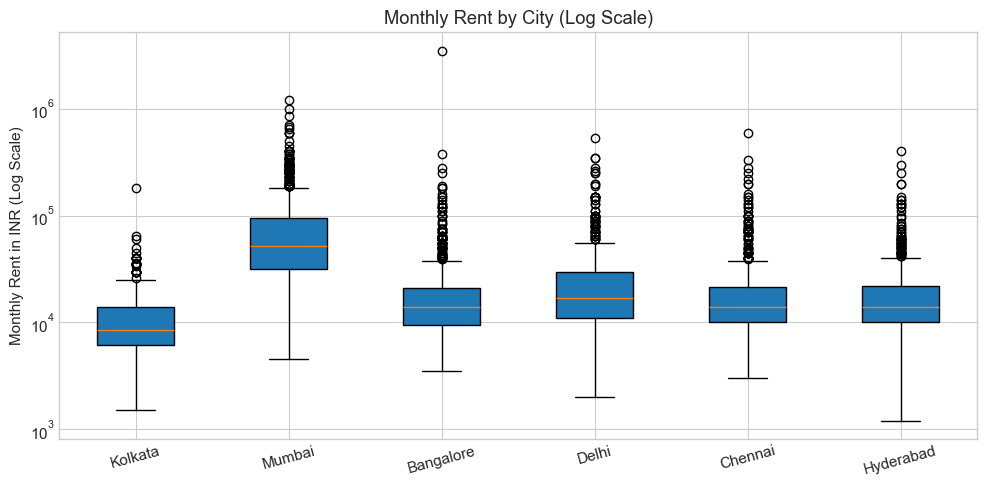

In [5]:
city_group = df_raw.groupby('City')['Rent'].agg(['count', 'median', 'mean', 'min', 'max'])
print('City-wise Rent Metrics:')
print(city_group)

cities = df_raw['City'].unique()
data_by_city = [df_raw[df_raw['City'] == c]['Rent'] for c in cities]

plt.figure(figsize=(10, 5))
plt.boxplot(data_by_city, tick_labels=cities, patch_artist=True)
plt.yscale('log')
plt.title('Monthly Rent by City (Log Scale)')
plt.ylabel('Monthly Rent in INR (Log Scale)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 6. Structural Features & Floor Parsing
Inspecting the `Floor` string patterns and demonstrating parsing into `floor_number` and `total_floors`.


In [6]:
from preprocessing import parse_floor_string

parsed = [parse_floor_string(f) for f in df_raw['Floor']]
df_raw['floor_number'] = [p[0] for p in parsed]
df_raw['total_floors'] = [p[1] for p in parsed]
df_raw['floor_ratio'] = df_raw['floor_number'] / df_raw['total_floors'].clip(lower=1)
print('Parsed floor summary:')
print(df_raw[['floor_number', 'total_floors', 'floor_ratio']].describe())


Parsed floor summary:
       floor_number  total_floors  floor_ratio
count   4746.000000   4742.000000  4742.000000
mean       3.436157      6.974272     0.454460
std        5.773950      9.469574     0.329246
min       -2.000000      1.000000    -2.000000
25%        1.000000      2.000000     0.222549
50%        2.000000      4.000000     0.500000
75%        3.000000      6.000000     0.666667
max       76.000000     89.000000     1.000000


## 7. Data Cleaning Pipeline
Applying 4 documented exclusion rules:
1. Deduplication of 8 duplicate listings (excluding Posted On)
2. Proposed domain rent ceiling (Rent > 2,000,000 INR/month, bounding model scope; isolates Row 1837 unverified Marathahalli listing at 35 Lakhs)
3. Dropping physical impossibilities in unit size (Size < 50 sq ft, 16 rows)
4. Dropping non-residential commercial hostel outlier (Bathroom > 7, 1 row: 1 BHK with 10 baths)


In [7]:
from preprocessing import clean_raw_data

df_clean, audit = clean_raw_data(df_raw)
print(f"Initial Rows: {audit['initial_rows']}")
print(f"Clean Rows:   {audit['final_rows']} ({audit['total_dropped']} dropped, {audit['retention_percentage']}%) retained")
print('\nExclusion details:')
for k, v in audit['exclusions'].items():
    print(f"  - {k}: {v['dropped_count']} rows ({v['rationale']})")


Initial Rows: 4746
Clean Rows:   4720 (26 dropped, 99.45%) retained

Exclusion details:
  - duplicate_listings_excluding_posted_on: 8 rows (Exact duplicate property listings published on different crawl dates.)
  - predeclared_economic_rent_ceiling_gt_2m_inr: 1 rows (Monthly rent exceeds proposed domain restriction of 2,000,000 INR (Row 1837: 3 BHK, 2500 sq ft, Marathahalli at 3,500,000 INR; unverified extreme outlier; scope bounded to leases <= 20L INR).)
  - impossible_unit_size_below_50_sqft: 16 rows (Physical impossibility for independent residential dwellings (e.g., 3 BHK with 10 sq ft).)
  - extreme_non_residential_bathroom_outlier: 1 rows (Commercial hostel / farmhouse outlier (1 BHK with 10 bathrooms in Beeramguda, Hyderabad).)


## 8. Train/Test Split & Preprocessing (Zero Data Leakage)
Executing 80/20 train/test split with stratification on `City`. Fitting encoders strictly on the training partition.


In [8]:
from preprocessing import split_train_test, RentalPreprocessor

train_df, test_df = split_train_test(df_clean, test_size=0.20, random_state=42)
print(f'Train rows: {len(train_df)} | Test rows: {len(test_df)}')

preprocessor = RentalPreprocessor()
preprocessor.fit(train_df)

X_train, y_train_raw, y_train_log = preprocessor.transform(train_df)
X_test, y_test_raw, y_test_log = preprocessor.transform(test_df)

print(f'X_train shape: {X_train.shape} | X_test shape: {X_test.shape}')
print('Feature names (21 total):', preprocessor.feature_names)


Train rows: 3776 | Test rows: 944
X_train shape: (3776, 21) | X_test shape: (944, 21)
Feature names (21 total): ['BHK', 'Size', 'Bathroom', 'floor_number', 'total_floors', 'floor_ratio', 'City_Bangalore', 'City_Chennai', 'City_Delhi', 'City_Hyderabad', 'City_Kolkata', 'City_Mumbai', 'Furnishing Status_Furnished', 'Furnishing Status_Semi-Furnished', 'Furnishing Status_Unfurnished', 'Tenant Preferred_Bachelors', 'Tenant Preferred_Bachelors/Family', 'Tenant Preferred_Family', 'Area Type_Built Area', 'Area Type_Carpet Area', 'Area Type_Super Area']


## 9. Conclusion & Transition to Phase 5C
- **Dataset**: House Rent Prediction Dataset (4,746 rows -> 4,720 clean rows, 99.45% retained).
- **Target**: Monthly rent in INR (`Rent`), stabilized via `log1p(Rent)` with skewness dropping from 21.41 to 0.91.
- **Features**: 21 features engineered (6 numeric, 15 one-hot encoded categories).
- **Partitions**: Disjoint 80/20 train (3,776 rows) and test (944 rows) saved in `ml/data/processed/`.
- **Status**: Ready for Phase 5C model training (Linear Regression, Random Forest, XGBoost).
